In [25]:
import matplotlib.pyplot as plt
from sklearn.metrics import root_mean_squared_error
from statsmodels.tsa.seasonal import seasonal_decompose
import pandas as pd
import numpy as np
from tqdm import tqdm

In [6]:
df=pd.read_csv("F:\MACHINE LEARNING\SOMETHING\Datasets\daily-total-female-births-in-cal.csv")
y=df['Daily total female births in California']
y_train,y_test=y.iloc[:-31],y.iloc[-31:]
y_train.shape

(334,)

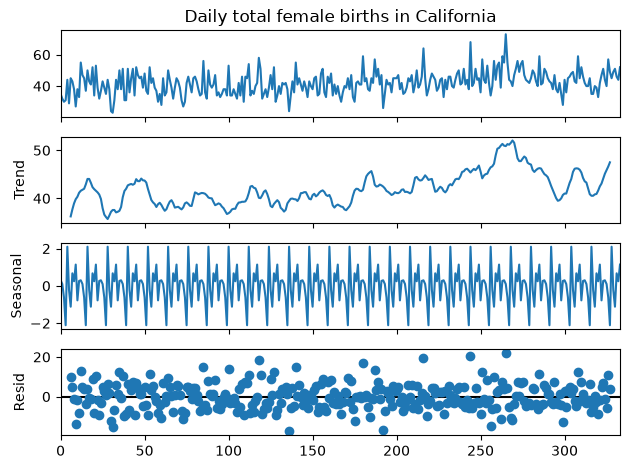

In [10]:
result=seasonal_decompose(y_train,model='additive',period=12)
result.plot()
plt.show()

In [15]:
from statsmodels.tsa.api import Holt
from statsmodels.tsa.api import SimpleExpSmoothing
from statsmodels.tsa.api import ExponentialSmoothing

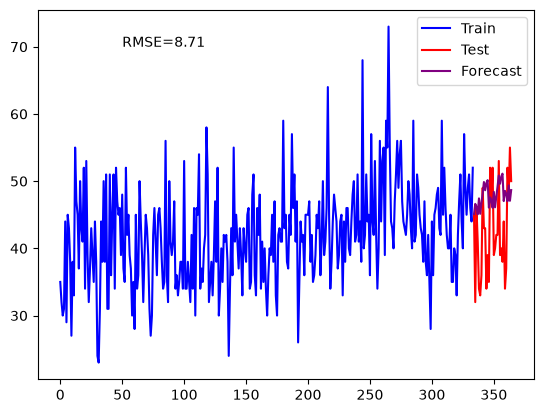

In [19]:
alpha , beta, gamma =  0.6, 0.2, 0.1
hw_add = ExponentialSmoothing(y_train, seasonal_periods= 12, trend = 'add', seasonal= 'add')
fit1 = hw_add.fit(smoothing_level = alpha, smoothing_trend= beta,optimized=False,smoothing_seasonal=gamma)
fcast1 = fit1.forecast(len(y_test))
y_train.plot(color = 'blue', label= 'Train')
y_test.plot(color = 'red', label = 'Test')
fcast1.plot(color = 'purple', label= 'Forecast')
rms=np.round(root_mean_squared_error(y_test,fcast1),2)
plt.text(50,70,f'RMSE={rms}')
plt.legend(loc='best')
plt.show()

C:\Users\PGCP-AI.STUDENTSDC\AppData\Local\anaconda3\Lib\site-packages\pandas\util\_decorators.py:213: EstimationWarning: Model has no free parameters to estimate. Set optimized=False to suppress this warning
  return func(*args, **kwargs)


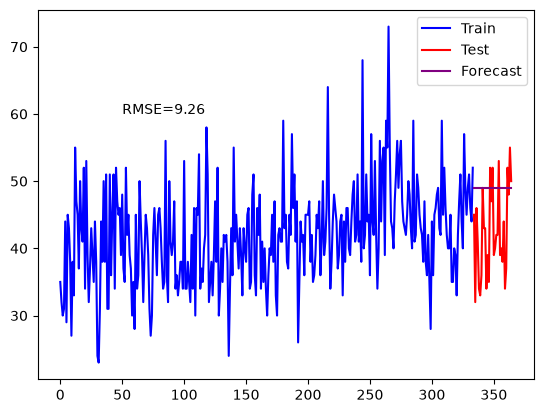

In [21]:
alpha = 0.5
ses = SimpleExpSmoothing(y_train)
fit1 = ses.fit(smoothing_level = alpha)
fcast1 = fit1.forecast(len(y_test))
y_train.plot(color = 'blue', label= 'Train')
y_test.plot(color = 'red', label = 'Test')
fcast1.plot(color = 'purple', label= 'Forecast')
rms=np.round(root_mean_squared_error(y_test,fcast1),2)
plt.text(50,60,f'RMSE={rms}')
plt.legend(loc='best')
plt.show()

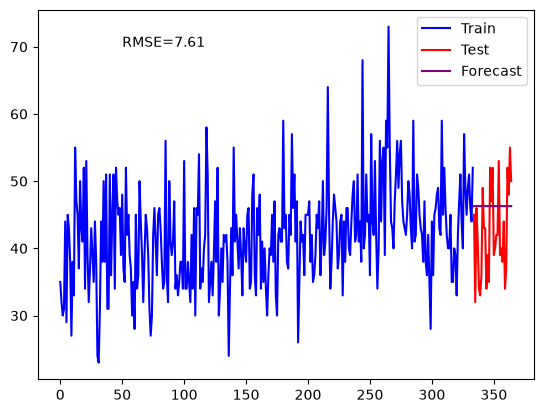

In [22]:
alpha , beta, phi=  0.1, 0.2, 0.3
holt = Holt(y_train, damped_trend= True, exponential= True)
fit1 = holt.fit(smoothing_level = alpha, smoothing_trend= beta,optimized=False,damping_trend=phi)
fcast1 = fit1.forecast(len(y_test))
y_train.plot(color = 'blue', label= 'Train')
y_test.plot(color = 'red', label = 'Test')
fcast1.plot(color = 'purple', label= 'Forecast')
rms=np.round(root_mean_squared_error(y_test,fcast1),2)
plt.text(50,70,f'RMSE={rms}')
plt.legend(loc='best')
plt.show()

In [27]:
alpha , beta, gamma =  np.linspace(0.01,0.99,10), np.linspace(0.01,0.99,10), np.linspace(0.01,0.99,10)
scores = []
for a in tqdm(alpha):
    for b in beta:
        for g in gamma:
            for s in ['add','mul']:
                hw_add = ExponentialSmoothing(y_train, seasonal_periods= 7, trend = 'add', seasonal= s)
                fit1 = hw_add.fit(smoothing_level = a, smoothing_trend= b,optimized=False,smoothing_seasonal=g)
                fcast1 = fit1.forecast(len(y_test))
                scores.append([a,b,g,s, root_mean_squared_error(y_test, fcast1)])
df_scores = pd.DataFrame(scores, columns= ['alpha', 'beta','gamma','seasonality','score'])
df_scores.sort_values('score')

100%|██████████| 10/10 [00:21<00:00,  2.18s/it]


,alpha,beta,gamma,seasonality,score
100,0.01,0.554444,0.010000,add,5.971335e+00
101,0.01,0.554444,0.010000,mul,6.275101e+00
83,0.01,0.445556,0.118889,mul,6.338646e+00
82,0.01,0.445556,0.118889,add,6.376915e+00
21,0.01,0.118889,0.010000,mul,6.677560e+00
...,...,...,...,...,...
1976,0.99,0.881111,0.881111,add,3.858421e+14
1958,0.99,0.772222,0.990000,add,2.873490e+15
1996,0.99,0.990000,0.881111,add,8.246102e+16
1978,0.99,0.881111,0.990000,add,7.364327e+17
